# Social Network Analysis with NetworkX

*Code examples based on Jan Kirenz's tutorial "Social Network Analysis with Python" (CC BY-SA 4.0).*

Social network analysis studies the **relationships** between people (or web pages, computers…).
- A network is a graph made of **nodes** (people) and **edges** (connections).
- In this notebook I build different types of networks and measure who is most connected or important.

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
#import warnings; warnings.simplefilter('ignore')

## 1. Three types of networks
- **Undirected (symmetric):** "works with" goes both ways. Built with `nx.Graph()`.

Number of nodes: 6
Number of edges: 8


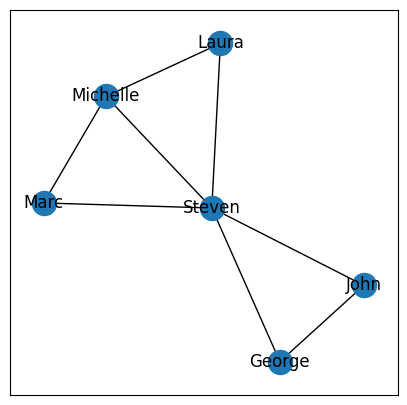

In [ ]:
# Create the graph object
G_symmetric = nx.Graph()  # Graph() will create an undirected graph

# Define the edges and nodes
G_symmetric.add_edge('Steven',  'Laura')
G_symmetric.add_edge('Steven',  'Marc')
G_symmetric.add_edge('Steven',  'John')
G_symmetric.add_edge('Steven',  'Michelle')
G_symmetric.add_edge('Laura',   'Michelle')
G_symmetric.add_edge('Michelle', 'Marc')
G_symmetric.add_edge('George',   'John')
G_symmetric.add_edge('George',   'Steven')

# Show basic info and visualize (Fixed)
print(f"Number of nodes: {G_symmetric.number_of_nodes()}")
print(f"Number of edges: {G_symmetric.number_of_edges()}")

plt.figure(figsize=(5, 5))
nx.spring_layout(G_symmetric)
nx.draw_networkx(G_symmetric)
plt.show()

- **Directed (asymmetric):** "follows on Instagram" doesn't have to go both ways. Built with `nx.DiGraph()`. A double arrow counts as **2 edges**, which is why there are 6 edges but only 5 lines.

Number of nodes: 5
Number of edges: 6


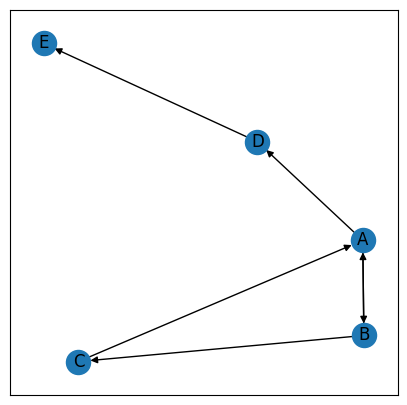

In [ ]:
# Create the graph object
G_asymmetric = nx.DiGraph()  # Note: DiGraph instead of just Graph

# Define the edges and nodes
G_asymmetric.add_edge('A', 'B')  # A->B
G_asymmetric.add_edge('B', 'A')  # B->A (not the same as above)
G_asymmetric.add_edge('B', 'C')
G_asymmetric.add_edge('A', 'D')
G_asymmetric.add_edge('C', 'A')
G_asymmetric.add_edge('D', 'E')

# Show info and visualize (Fixed)
print(f"Number of nodes: {G_asymmetric.number_of_nodes()}")
print(f"Number of edges: {G_asymmetric.number_of_edges()}")

plt.figure(figsize=(5, 5))
nx.spring_layout(G_asymmetric)
nx.draw_networkx(G_asymmetric)
plt.show()

- **Weighted:** each edge has a strength, e.g. the number of projects done together. I drew heavy edges (> 8) as solid lines and light ones as dashed lines.

In [ ]:
# Create the graph object
G_weighted = nx.Graph() # Replace by DiGraph for directed graphs

# Define the edges and nodes
G_weighted.add_edge('Steven',  'Laura',   weight=25)
G_weighted.add_edge('Steven',  'Marc',    weight=8)
G_weighted.add_edge('Steven',  'John',    weight=11)
G_weighted.add_edge('Steven',  'Michelle',weight=1)
G_weighted.add_edge('Laura',   'Michelle',weight=1)
G_weighted.add_edge('Michelle','Marc',    weight=1)
G_weighted.add_edge('George',  'John',    weight=8)
G_weighted.add_edge('George',  'Steven',  weight=4)

Number of nodes: 6
Number of edges: 8


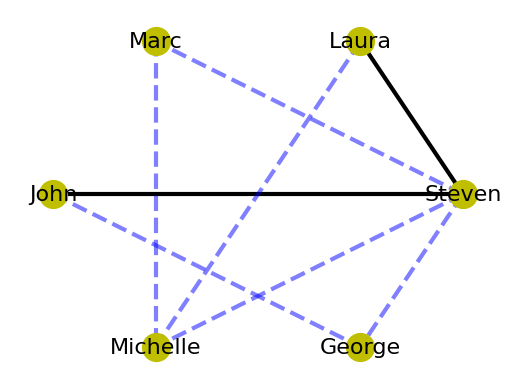

In [ ]:
# Show info and visualize (Fixed)
print(f"Number of nodes: {G_weighted.number_of_nodes()}")
print(f"Number of edges: {G_weighted.number_of_edges()}")

# Do these instead of just nx.draw_networkx(G_weighted) to visualize the weights
# Define two lists of edge to be applied different styles depending on weight
elarge = [(u, v) for (u, v, d) in G_weighted.edges(data=True) if d['weight'] > 8]
esmall = [(u, v) for (u, v, d) in G_weighted.edges(data=True) if d['weight'] <= 8]

pos = nx.circular_layout(G_weighted)  # positions for all nodes

# nodes
nx.draw_networkx_nodes(G_weighted, pos, node_size=400, node_color='y')
# edges
nx.draw_networkx_edges(G_weighted, pos, edgelist=elarge, width=3)
nx.draw_networkx_edges(G_weighted, pos, edgelist=esmall, width=3, alpha=0.5, edge_color='b', style='dashed')
# labels
nx.draw_networkx_labels(G_weighted, pos, font_size=16, font_family='sans-serif')

plt.axis('off')
plt.show()

## 2. Degree — how many connections?
Degree is the number of edges touching a node. Steven has 5 connections, Michelle 3 and George 2.
- In a directed graph, both directions count, so A = 4.
- **Weights don't change degree.** It only counts edges.

In [ ]:
nx.degree(G_symmetric, 'Michelle')

3

In [ ]:
nx.degree(G_symmetric, 'Steven')

5

In [ ]:
nx.degree(G_symmetric, 'George')

2

In [ ]:
nx.degree(G_asymmetric, 'A')

4

In [ ]:
nx.degree(G_asymmetric, 'C')

2

In [ ]:
nx.degree(G_weighted, 'Steven')

5

In [ ]:
nx.degree(G_weighted, 'John')

2

## 3. Clustering coefficient — are my friends also friends?
Local clustering = (links between my neighbours) / (possible links between them).
- **Michelle:** she has 3 neighbours, and 2 of the 3 possible pairs are connected, so her clustering coefficient is **0.67**.
- **Laura:** her neighbours are all connected to each other, so hers is **1.0**.

The average over the whole network is 0.83, so this group is very tightly connected.

In [ ]:
nx.clustering(G_symmetric,'Michelle')

0.6666666666666666

In [ ]:
nx.clustering(G_symmetric,'Laura')

1.0

In [ ]:
nx.average_clustering(G_symmetric)

0.8277777777777778

In [ ]:
nx.clustering(G_asymmetric, 'B')

0.5

In [ ]:
nx.clustering(G_asymmetric, 'C')

1.0

## 4. Distance measures
- **Shortest path:** Michelle → Steven → John, which is 2 steps. In a directed graph a path must follow the arrow directions, so some paths don't exist.
- **Breadth-first search (BFS):** explores the network level by level from one person. This shows how information would spread from them.
- **Eccentricity:** the longest shortest-path from a node. Steven's is 1 because he is directly linked to everyone, and Michelle's is 2.

In [ ]:
nx.shortest_path(G_symmetric, 'Michelle', 'John')

['Michelle', 'Steven', 'John']

In [ ]:
nx.shortest_path_length(G_symmetric, 'Michelle', 'John')

2

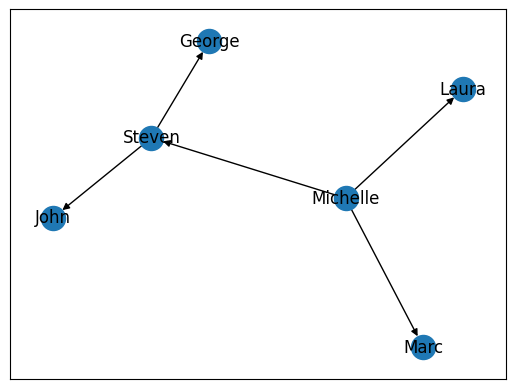

In [ ]:
M = nx.bfs_tree(G_symmetric, 'Michelle')
nx.draw_networkx(M)

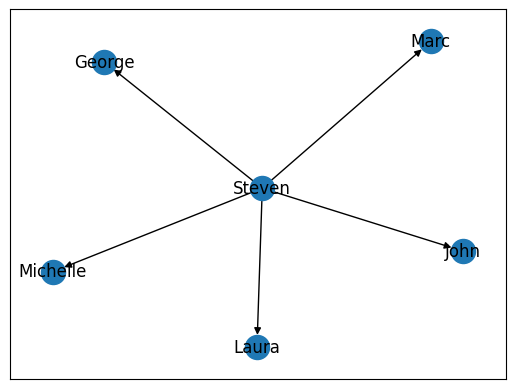

In [ ]:
S = nx.bfs_tree(G_symmetric, 'Steven')
nx.draw_networkx(S)

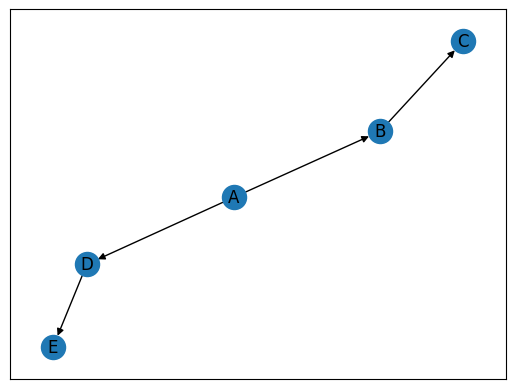

In [ ]:
S = nx.bfs_tree(G_asymmetric, 'A')
nx.draw_networkx(S)

Eccentricity = 2


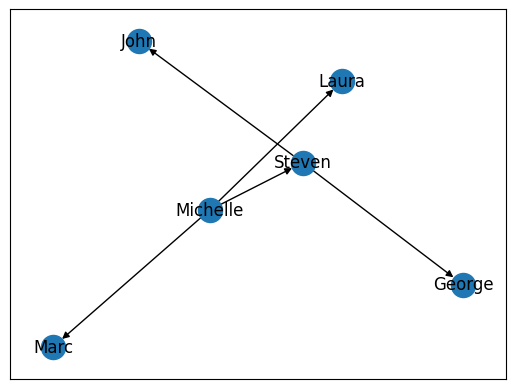

In [ ]:
print(f"Eccentricity = {nx.eccentricity(G_symmetric,'Michelle')}")
S = nx.bfs_tree(G_symmetric, 'Michelle')
nx.draw_networkx(S)

Eccentricity = 1


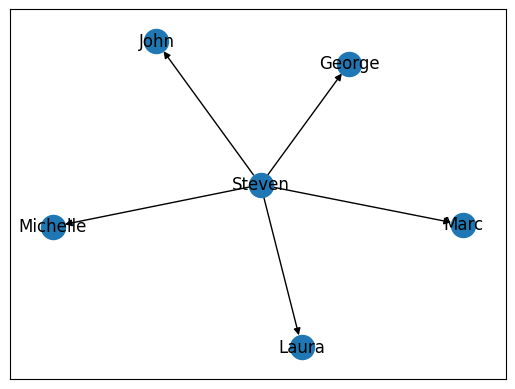

In [ ]:
print(f"Eccentricity = {nx.eccentricity(G_symmetric,'Steven')}")
S = nx.bfs_tree(G_symmetric, 'Steven')
nx.draw_networkx(S)

## 5. Centrality — who is important?
| Measure | Idea | Top person |
|---|---|---|
| Degree | most connections | Steven (1.0) |
| Eigenvector | connected to other important people | Steven (0.60) |
| Closeness | shortest average distance to everyone | Steven (1.0) |
| Betweenness | sits on many shortest paths (a "bridge") | Steven (0.65) |

Steven ranks first on every measure, because he is the hub of this small network. Laura, Marc, John and George have betweenness 0: no shortest path needs to pass through them.

In [ ]:
nx.degree_centrality(G_symmetric)

{'Steven': 1.0,
 'Laura': 0.4,
 'Marc': 0.4,
 'John': 0.4,
 'Michelle': 0.6000000000000001,
 'George': 0.4}

In [ ]:
nx.eigenvector_centrality(G_symmetric)

{'Steven': 0.6006686104947807,
 'Laura': 0.35456776607980744,
 'Marc': 0.35456776607980744,
 'John': 0.3084459243342467,
 'Michelle': 0.4443904166426226,
 'George': 0.3084459243342467}

In [ ]:
nx.closeness_centrality(G_symmetric)

{'Steven': 1.0,
 'Laura': 0.625,
 'Marc': 0.625,
 'John': 0.625,
 'Michelle': 0.7142857142857143,
 'George': 0.625}

In [ ]:
nx.betweenness_centrality(G_symmetric)

{'Steven': 0.65,
 'Laura': 0.0,
 'Marc': 0.0,
 'John': 0.0,
 'Michelle': 0.05,
 'George': 0.0}

## What I learned
- Pick the right graph type (undirected, directed or weighted) for the relationship.
- Different centrality measures answer different questions, so the "most important" person depends on the measure:
  - who is popular (degree)
  - who is well connected to other important people (eigenvector)
  - who can reach everyone fastest (closeness)
  - who is a bridge (betweenness)
- In education, the same analysis could find isolated students in a class discussion network or the students who connect groups together.